# Pilot: confidence cascade of two CNN agents on Cassava leaf disease classification

Pilot run for the Results section of the article *Multi-Agent AI System for Plant Disease Classification*. It uses a 10% subset of the Cassava training and validation splits and the full test split, two base agents (MobileNetV2, ResNet50), and three random seeds (0, 1, 2). Configurations compared: each agent alone, soft voting, and a confidence cascade (MobileNetV2 first, escalation to soft voting when the confidence is below a threshold tau).

Runtime: Google Colab, T4 GPU.

## 1. Setup
Installs a package that is missing in the Colab runtime and removes a partly downloaded copy of the dataset.

## 2. Data
Loads the `cassava` dataset from TensorFlow Datasets with `train[:10%]`, `validation[:10%]` and the full `test` split. Prints the size of each split and the number of images per class (cbb, cbsd, cgm, cmd, healthy).

In [1]:
!pip install -q importlib_resources
!rm -rf /root/tensorflow_datasets/cassava

## 3. Base agents
Defines the preprocessing (resize to 224x224, model-specific input scaling) and the agent model: an ImageNet-pre-trained backbone (frozen) with a new dropout and softmax classification head. This cell also runs a first training of MobileNetV2 and ResNet50 (5 epochs, Adam) and prints test accuracy and macro-F1 for each.

In [2]:
import tensorflow_datasets as tfds
import numpy as np

(train, val, test), info = tfds.load(
    "cassava",
    split=["train[:10%]", "validation[:10%]", "test"],
    as_supervised=True,
    with_info=True,
)
names = info.features["label"].names
print(names)
for n, d in [("train", train), ("val", val), ("test", test)]:
    y = np.array([int(l) for _, l in d])
    print(n, len(y), np.bincount(y, minlength=len(names)))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.WHT7I8_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.WHT7I8_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.WHT7I8_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
train 566 [ 32 157  76 265  36]
val 189 [14 49 31 90  5]
test 1885 [155 481 258 886 105]


In [3]:
import tensorflow as tf, numpy as np
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as prep_m
from tensorflow.keras.applications.resnet50 import preprocess_input as prep_r
from sklearn.metrics import f1_score

tf.keras.utils.set_random_seed(0)
K = len(names)

def make_ds(d, prep, shuffle=False):
    def f(x, y):
        x = tf.image.resize(x, (224, 224))
        return prep(tf.cast(x, tf.float32)), y
    d = d.map(f, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        d = d.shuffle(1000, seed=0)
    return d.batch(32).prefetch(tf.data.AUTOTUNE)

def build(base_cls):
    base = base_cls(include_top=False, weights="imagenet",
                    input_shape=(224, 224, 3), pooling="avg")
    base.trainable = False
    out = layers.Dense(K, activation="softmax")(layers.Dropout(0.2)(base.output))
    m = models.Model(base.input, out)
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

probs = {}
for name, cls, prep in [("MobileNetV2", MobileNetV2, prep_m),
                        ("ResNet50", ResNet50, prep_r)]:
    m = build(cls)
    m.fit(make_ds(train, prep, True), validation_data=make_ds(val, prep),
          epochs=5, verbose=2)
    test_ds = make_ds(test, prep)
    probs[name] = m.predict(test_ds, verbose=0)
    y_test = np.concatenate([yy.numpy() for _, yy in test_ds])
    f1 = f1_score(y_test, probs[name].argmax(1), average="macro")
    acc = (probs[name].argmax(1) == y_test).mean()
    print(f"{name}: accuracy={acc:.4f}, macro-F1={f1:.4f}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
18/18 - 44s - 2s/step - accuracy: 0.4452 - loss: 1.4788 - val_accuracy: 0.5556 - val_loss: 1.1627
Epoch 2/5
18/18 - 3s - 152ms/step - accuracy: 0.5742 - loss: 1.0998 - val_accuracy: 0.6085 - val_loss: 1.0218
Epoch 3/5
18/18 - 5s - 293ms/step - accuracy: 0.6307 - loss: 0.9408 - val_accuracy: 0.6508 - val_loss: 0.9455
Epoch 4/5
18/18 - 3s - 142ms/step - accuracy: 0.6714 - loss: 0.8403 - val_accuracy: 0.6667 - val_loss: 0.8962
Epoch 5/5
18/18 - 3s - 152ms/step - accuracy: 0.7208 - loss: 0.7726 - val_accuracy: 0.6667 - val_loss: 0.8990
MobileNetV2: accuracy=0.6727, macro-F1=0.4718
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
18/18 - 34s - 2s/step - accuracy: 0.4700 - loss: 1.4754 - val_accuracy: 0.6349 - val_loss: 1.0300
Epoch 2/5
18/18 - 5s - 281ms/step - accuracy: 0.6060 - loss: 1.0284 - val_accuracy: 0.6614 - val_loss: 0.9649
Epoch 3/5
18/18 - 5s - 255ms/step - accuracy: 0.6625 - loss: 0.8898 - val_accuracy: 0.65

## 4. Three seeds: single agents, soft voting, cascade
For each seed (0, 1, 2) both agents are retrained and their class probabilities on the validation and test splits are saved. Configurations evaluated on the test split by macro-F1:

- each agent alone,
- soft voting (mean of the two probability vectors),
- cascade: MobileNetV2 predicts when its maximum probability is at least tau, otherwise the soft-voting prediction is used.

The threshold tau is chosen per seed on the validation split only: the smallest value on the grid 0.30 to 1.00 (step 0.05) for which the cascade macro-F1 is at most 0.01 below that of soft voting. The table reports tau, the escalation rate rho (share of test images sent to the second stage), and the macro-F1 per seed, followed by mean and sample standard deviation.

In [4]:
def make_ds(d, prep, shuffle=False, seed=0):
    def f(x, y):
        x = tf.image.resize(x, (224, 224))
        return prep(tf.cast(x, tf.float32)), y
    d = d.map(f, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        d = d.shuffle(1000, seed=seed)
    return d.batch(32).prefetch(tf.data.AUTOTUNE)

yv = np.concatenate([y.numpy() for _, y in make_ds(val, prep_m)])
yt = np.concatenate([y.numpy() for _, y in make_ds(test, prep_m)])
mf1 = lambda y, p: f1_score(y, p, average="macro")

def casc(pM, pE, tau):
    esc = pM.max(1) < tau
    return np.where(esc, pE.argmax(1), pM.argmax(1)), esc.mean()

taus = np.round(np.arange(0.3, 1.0001, 0.05), 2)
allp, rows, kept = {}, [], {}

for seed in [0, 1, 2]:
    P = {}
    for key, cls, prep in [("M", MobileNetV2, prep_m), ("R", ResNet50, prep_r)]:
        tf.keras.utils.set_random_seed(seed)
        m = build(cls)
        m.fit(make_ds(train, prep, True, seed),
              validation_data=make_ds(val, prep), epochs=5, verbose=0)
        P[key] = (m.predict(make_ds(val, prep), verbose=0),
                  m.predict(make_ds(test, prep), verbose=0))
        kept[(seed, key)] = m                      # models are needed in Section 9
    allp[seed] = P
    (Mv, Mt), (Rv, Rt) = P["M"], P["R"]
    Ev, Et = (Mv + Rv) / 2, (Mt + Rt) / 2          # soft voting
    target = mf1(yv, Ev.argmax(1)) - 0.01           # tau chosen on VAL only
    tau = [t for t in taus if mf1(yv, casc(Mv, Ev, t)[0]) >= target][0]
    pred, rho = casc(Mt, Et, tau)
    rows.append(dict(seed=seed, tau=tau, rho=rho,
                     MobileNetV2=mf1(yt, Mt.argmax(1)),
                     ResNet50=mf1(yt, Rt.argmax(1)),
                     SoftVoting=mf1(yt, Et.argmax(1)),
                     Cascade=mf1(yt, pred)))
    print("seed", seed, "done")

import pandas as pd
df = pd.DataFrame(rows)
print(df.round(4))
print(df.drop(columns="seed").agg(["mean", "std"]).round(4))

seed 0 done
seed 1 done
seed 2 done
   seed   tau     rho  MobileNetV2  ResNet50  SoftVoting  Cascade
0     0  0.60  0.3613       0.4718    0.5367      0.5255   0.5137
1     1  0.65  0.5215       0.5315    0.5666      0.5752   0.5718
2     2  0.35  0.0334       0.5063    0.5679      0.5594   0.5162
         tau     rho  MobileNetV2  ResNet50  SoftVoting  Cascade
mean  0.5333  0.3054       0.5032    0.5570      0.5533   0.5339
std   0.1607  0.2488       0.0300    0.0177      0.0254   0.0329


## 5. Additional analyses
1. Sensitivity of the cascade to tau: test macro-F1 against escalation rate rho (mean over seeds); the figure is saved as `tau_sensitivity.pdf`. This curve is descriptive and is not used to choose tau.
2. Error analysis for seed 0: per-class F1 of ResNet50, soft voting and the cascade, and the confusion matrix of the cascade (`confusion_cascade.pdf`).
3. CPU latency per image at batch size 1 (median of 60 forward passes after 5 warm-up passes, random weights, forward pass only). The expected cascade latency is computed as t_M + rho * t_R using the measured values.

     tau    rho  macroF1
0   0.30  0.009   0.5045
1   0.35  0.039   0.5110
2   0.40  0.094   0.5237
3   0.45  0.169   0.5284
4   0.50  0.253   0.5357
5   0.55  0.332   0.5448
6   0.60  0.405   0.5485
7   0.65  0.477   0.5506
8   0.70  0.552   0.5509
9   0.75  0.628   0.5524
10  0.80  0.699   0.5530
11  0.85  0.773   0.5533
12  0.90  0.862   0.5533
13  0.95  0.946   0.5533
14  1.00  1.000   0.5533
Per-class F1 (seed 0):
ResNet50 {'cbb': np.float64(0.102), 'cbsd': np.float64(0.681), 'cgm': np.float64(0.441), 'cmd': np.float64(0.836), 'healthy': np.float64(0.623)}
SoftVoting {'cbb': np.float64(0.049), 'cbsd': np.float64(0.685), 'cgm': np.float64(0.424), 'cmd': np.float64(0.839), 'healthy': np.float64(0.63)}
Cascade {'cbb': np.float64(0.025), 'cbsd': np.float64(0.674), 'cgm': np.float64(0.421), 'cmd': np.float64(0.833), 'healthy': np.float64(0.615)}
test size: 1885 per class: [155 481 258 886 105]
tM=255.8 ms, tR=456.4 ms, rho=0.305, expected cascade=395.2 ms, soft voting=712.2 ms


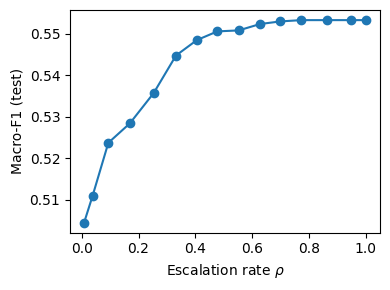

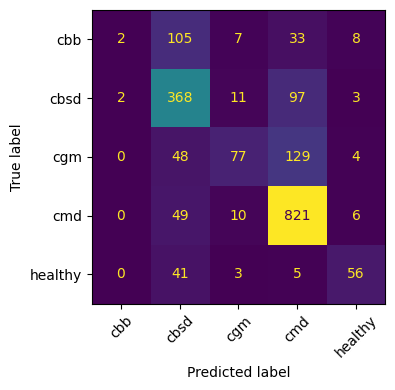

In [5]:
import matplotlib.pyplot as plt, time
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1) sensitivity of the cascade to tau (test set, mean over seeds)
res = {t: [] for t in taus}
for s, P in allp.items():
    (Mv, Mt), (Rv, Rt) = P["M"], P["R"]
    Et = (Mt + Rt) / 2
    for t in taus:
        pr, rho = casc(Mt, Et, t)
        res[t].append((mf1(yt, pr), rho))
f1m = [np.mean([a for a, _ in res[t]]) for t in taus]
rhm = [np.mean([b for _, b in res[t]]) for t in taus]
fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(rhm, f1m, "o-")
ax.set_xlabel("Escalation rate $\\rho$")
ax.set_ylabel("Macro-F1 (test)")
fig.tight_layout(); fig.savefig("tau_sensitivity.pdf")
print(pd.DataFrame({"tau": taus, "rho": np.round(rhm, 3), "macroF1": np.round(f1m, 4)}))

# 2) error analysis: seed 0, soft voting and cascade
(Mv, Mt), (Rv, Rt) = allp[0]["M"], allp[0]["R"]
Et = (Mt + Rt) / 2
pc, _ = casc(Mt, Et, rows[0]["tau"])
print("Per-class F1 (seed 0):")
for nm, pr in [("ResNet50", Rt.argmax(1)), ("SoftVoting", Et.argmax(1)), ("Cascade", pc)]:
    print(nm, dict(zip(names, np.round(f1_score(yt, pr, average=None), 3))))
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(yt, pc), display_labels=names).plot(ax=ax, xticks_rotation=45, colorbar=False)
fig.tight_layout(); fig.savefig("confusion_cascade.pdf")
print("test size:", len(yt), "per class:", np.bincount(yt))

# 3) CPU latency, batch size 1 (weights do not matter for timing)
def lat(base_cls, prep, n=60):
    m = base_cls(include_top=False, weights=None, input_shape=(224, 224, 3), pooling="avg")
    x = np.random.rand(1, 224, 224, 3).astype("float32")
    with tf.device("/CPU:0"):
        for _ in range(5): m(x, training=False)
        t = []
        for _ in range(n):
            a = time.perf_counter(); m(x, training=False); t.append(time.perf_counter() - a)
    return np.median(t) * 1000
tM, tR = lat(MobileNetV2, prep_m), lat(ResNet50, prep_r)
rho = df["rho"].mean()
print(f"tM={tM:.1f} ms, tR={tR:.1f} ms, rho={rho:.3f}, expected cascade={tM + rho * tR:.1f} ms, soft voting={tM + tR:.1f} ms")

In [6]:
for n, d in [("train", train), ("val", val), ("test", test)]:
    y = np.array([int(l) for _, l in d])
    print(n, len(y), dict(zip(names, np.bincount(y, minlength=len(names)))))

train 566 {'cbb': np.int64(32), 'cbsd': np.int64(157), 'cgm': np.int64(76), 'cmd': np.int64(265), 'healthy': np.int64(36)}
val 189 {'cbb': np.int64(14), 'cbsd': np.int64(49), 'cgm': np.int64(31), 'cmd': np.int64(90), 'healthy': np.int64(5)}
test 1885 {'cbb': np.int64(155), 'cbsd': np.int64(481), 'cgm': np.int64(258), 'cmd': np.int64(886), 'healthy': np.int64(105)}


## 6. Save predictions and artefacts
Writes everything the later analyses need to `pilot_artifacts/`: for each seed the validation and test class probabilities of both agents, the hard predictions of every configuration, and the threshold `tau`. These files are small and should be committed. The seed-0 models are saved to `models_tmp/` for the end-to-end latency run in Section 9; they are large (ResNet50 is about 95 MB), so **do not commit `models_tmp/`**.

In [7]:
import os
os.makedirs("pilot_artifacts", exist_ok=True)
os.makedirs("models_tmp", exist_ok=True)

for seed, P in allp.items():
    (Mv, Mt), (Rv, Rt) = P["M"], P["R"]
    Et = (Mt + Rt) / 2
    r = rows[seed]
    pc, _ = casc(Mt, Et, r["tau"])
    np.savez_compressed(
        f"pilot_artifacts/preds_seed{seed}.npz",
        y_true=yt, y_val=yv,
        mobilenet=Mt.argmax(1), resnet=Rt.argmax(1),
        softvoting=Et.argmax(1), cascade=pc, tau=r["tau"],
        p_mobilenet_val=Mv, p_resnet_val=Rv,
        p_mobilenet_test=Mt, p_resnet_test=Rt)
df.to_csv("pilot_artifacts/pilot_v1_per_seed.csv", index=False)

# seed-0 models for the end-to-end latency run (kept in memory by the Section 4 loop)
kept[(0, "M")].save("models_tmp/model_M_seed0.keras")
kept[(0, "R")].save("models_tmp/model_R_seed0.keras")
print(sorted(os.listdir("pilot_artifacts")), sorted(os.listdir("models_tmp")))

['pilot_v1_per_seed.csv', 'preds_seed0.npz', 'preds_seed1.npz', 'preds_seed2.npz'] ['model_M_seed0.keras', 'model_R_seed0.keras']


## 7. Statistical tests on the pilot predictions (bootstrap, McNemar, Holm)
For every seed and every pair of configurations:

- **Paired bootstrap** (1,000 resamples of the test images; the same resamples are used for all pairs of a seed): 95% percentile interval for the difference in macro-F1.
- **Exact McNemar test** on per-image correctness (two-sided binomial test on the discordant pairs).
- **Holm correction** of the McNemar p-values across the four comparisons of a seed.

The interval and the test quantify the uncertainty due to the *test sample* within one trained model. The variation between seeds (retraining) is reported separately as mean ± SD; the three seeds share the same test set, so their intervals are not independent and are not pooled.

McNemar tests per-image *correctness* (accuracy), the bootstrap interval is on *macro-F1*; with rare classes such as CBB the two can disagree, so both are reported.

In [8]:
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
from scipy.stats import binomtest

B = 1000
SEEDS = [0, 1, 2]

def macro_f1_fast(y, p, K):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return np.divide(2 * tp, den, out=np.zeros(K), where=den > 0).mean()

def holm(pvals):
    p = np.asarray(pvals, float); m = len(p)
    order = np.argsort(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def paired_stats(y, preds, comparisons, K, seed, B=B):
    """preds: dict name -> hard predictions. Returns a DataFrame, one row per comparison."""
    n = len(y)
    idx = np.random.default_rng(1000 + seed).integers(0, n, size=(B, n))
    out = []
    for A, Bn in comparisons:
        pa, pb = preds[A], preds[Bn]
        obs = macro_f1_fast(y, pa, K) - macro_f1_fast(y, pb, K)
        boots = np.array([macro_f1_fast(y[i], pa[i], K) - macro_f1_fast(y[i], pb[i], K) for i in idx])
        lo, hi = np.percentile(boots, [2.5, 97.5])
        a_ok, b_ok = pa == y, pb == y
        n01, n10 = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
        p = 1.0 if n01 + n10 == 0 else binomtest(n01, n01 + n10, 0.5).pvalue
        out.append(dict(seed=seed, comparison=f"{A} - {Bn}", diff=obs, ci_lo=lo, ci_hi=hi,
                        ci_excludes_0=bool(lo > 0 or hi < 0),
                        A_only_correct=n01, B_only_correct=n10, p_mcnemar=p))
    res = pd.DataFrame(out)
    res["p_holm"] = holm(res["p_mcnemar"])
    return res

def summarize(stats):
    g = stats.groupby("comparison", sort=False)
    return pd.DataFrame({
        "mean_diff": g["diff"].mean(),
        "CI_excludes_0 (seeds)": g["ci_excludes_0"].sum().astype(int).astype(str) + f"/{stats.seed.nunique()}",
        "Holm p<0.05 (seeds)": g["p_holm"].apply(lambda s: int((s < 0.05).sum())).astype(str) + f"/{stats.seed.nunique()}",
        "min_p_holm": g["p_holm"].min()}).round(4)

COMPS_V1 = [("cascade", "softvoting"), ("cascade", "resnet"),
            ("cascade", "mobilenet"), ("softvoting", "resnet")]
stats_v1 = []
for s in SEEDS:
    d = np.load(f"pilot_artifacts/preds_seed{s}.npz")
    d = {k: d[k] for k in d.files}
    stats_v1.append(paired_stats(d["y_true"].astype(int),
                                 {k: d[k].astype(int) for k in ("mobilenet", "resnet", "softvoting", "cascade")},
                                 COMPS_V1, len(names), s))
stats_v1 = pd.concat(stats_v1, ignore_index=True)
stats_v1.to_csv("pilot_artifacts/stats_v1.csv", index=False)
print(stats_v1.round(4).to_string(index=False))
print()
print(summarize(stats_v1))

 seed           comparison    diff   ci_lo   ci_hi  ci_excludes_0  A_only_correct  B_only_correct  p_mcnemar  p_holm
    0 cascade - softvoting -0.0118 -0.0218 -0.0041           True               4              17     0.0072  0.0216
    0     cascade - resnet -0.0230 -0.0465 -0.0031           True              90              91     1.0000  1.0000
    0  cascade - mobilenet  0.0419  0.0179  0.0640           True             110              54     0.0000  0.0001
    0  softvoting - resnet -0.0112 -0.0326  0.0074          False              86              74     0.3846  0.7691
    1 cascade - softvoting -0.0034 -0.0100  0.0014          False               4               3     1.0000  1.0000
    1     cascade - resnet  0.0052 -0.0137  0.0269          False              99              68     0.0200  0.0600
    1  cascade - mobilenet  0.0403  0.0141  0.0667           True             122              73     0.0006  0.0022
    1  softvoting - resnet  0.0086 -0.0099  0.0294          Fals

## 8. Stacking (A2), temperature scaling and the calibrated cascade
Adds the two components that were missing in the pilot, using only the *frozen* base agents trained in Section 4:

1. **Temperature scaling.** One temperature per agent, fitted on the validation split by minimising the negative log-likelihood. It is applied to the stored softmax outputs via `softmax(log p / T)`, which is identical to scaling the logits. Calibration is reported as the expected calibration error (ECE, 15 bins) before and after.
2. **Stacking (A2).** Multinomial logistic regression on the concatenated calibrated probabilities `[p_M; p_R]`, fitted on the validation split (the pilot has no separate meta split; this is a deviation from the plan).
3. **Calibrated cascade (A3').** MobileNetV2 predicts if its *calibrated* confidence is at least `tau`; otherwise the stacking prediction is used. `tau` is the smallest value on the 0.30 to 1.00 grid (step 0.05) for which the validation macro-F1 of the cascade is at most 0.01 below that of stacking. Because the meta-classifier is fitted on the validation split, the validation macro-F1 of stacking is computed from **5-fold out-of-fold predictions**, otherwise it would be optimistic.

The original pilot configurations (raw-softmax cascade, soft voting) are kept in the table for comparison. All numbers come from the same trained models. The H2 check at the end uses the non-inferiority margin of 0.5 macro-F1 points: it is met in a seed only if the lower bound of the bootstrap interval of `cascade_cal - stacking` is above -0.005.

In [9]:
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

EPS = 1e-12
K = len(names)
taus = np.round(np.arange(0.3, 1.0001, 0.05), 2)

def temp_scale(p, T):
    z = np.log(np.clip(p, EPS, 1.0)) / T
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def fit_T(p, y):
    nll = lambda lt: -np.log(temp_scale(p, np.exp(lt))[np.arange(len(y)), y] + EPS).mean()
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))

def ece(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e

def mf1_(y, p): return f1_score(y, p, average="macro")

rows_v2, stats_v2, cal_rows = [], [], []
COMPS_V2 = [("cascade_cal", "stacking"), ("cascade_cal", "resnet"), ("stacking", "resnet"),
            ("stacking", "softvoting"), ("cascade_cal", "cascade")]

for s in SEEDS:
    d = np.load(f"pilot_artifacts/preds_seed{s}.npz")
    yv_, yt_ = d["y_val"].astype(int), d["y_true"].astype(int)
    Mv, Mt, Rv, Rt = d["p_mobilenet_val"], d["p_mobilenet_test"], d["p_resnet_val"], d["p_resnet_test"]

    TM, TR = fit_T(Mv, yv_), fit_T(Rv, yv_)
    Mv_c, Mt_c, Rv_c, Rt_c = temp_scale(Mv, TM), temp_scale(Mt, TM), temp_scale(Rv, TR), temp_scale(Rt, TR)
    cal_rows.append(dict(seed=s, T_M=TM, T_R=TR,
                         ECE_M_raw=ece(Mt, yt_), ECE_M_cal=ece(Mt_c, yt_),
                         ECE_R_raw=ece(Rt, yt_), ECE_R_cal=ece(Rt_c, yt_)))

    Xv, Xt = np.hstack([Mv_c, Rv_c]), np.hstack([Mt_c, Rt_c])
    n_splits = int(max(2, min(5, np.bincount(yv_, minlength=K)[np.bincount(yv_, minlength=K) > 0].min())))
    lr = LogisticRegression(max_iter=2000, random_state=s)
    oof = cross_val_predict(lr, Xv, yv_, cv=StratifiedKFold(n_splits, shuffle=True, random_state=s),
                            method="predict_proba")
    lr.fit(Xv, yv_)                                   # final meta-classifier on the whole validation split
    St = lr.predict_proba(Xt)                         # stacking probabilities on test

    def casc_cal(pM_cal, pS, tau):
        esc = pM_cal.max(1) < tau
        return np.where(esc, pS.argmax(1), pM_cal.argmax(1)), esc.mean()

    target = mf1_(yv_, oof.argmax(1)) - 0.01          # tau on VAL only, vs out-of-fold stacking
    ok = [t for t in taus if mf1_(yv_, casc_cal(Mv_c, oof, t)[0]) >= target]
    tau2 = ok[0] if ok else taus[-1]
    pc2, rho2 = casc_cal(Mt_c, St, tau2)

    preds = dict(mobilenet=d["mobilenet"].astype(int), resnet=d["resnet"].astype(int),
                 softvoting=d["softvoting"].astype(int), cascade=d["cascade"].astype(int),
                 stacking=St.argmax(1), cascade_cal=pc2)
    np.savez_compressed(f"pilot_artifacts/preds_v2_seed{s}.npz", y_true=yt_, tau_cal=tau2, rho_cal=rho2,
                        T_M=TM, T_R=TR, **preds)
    rows_v2.append(dict(seed=s, tau_raw=float(d["tau"]), tau_cal=tau2, rho_cal=rho2,
                        **{k: mf1_(yt_, v) for k, v in preds.items()}))
    stats_v2.append(paired_stats(yt_, preds, COMPS_V2, K, s))

df2 = pd.DataFrame(rows_v2)
cal = pd.DataFrame(cal_rows)
stats_v2 = pd.concat(stats_v2, ignore_index=True)
df2.to_csv("pilot_artifacts/pilot_v2_per_seed.csv", index=False)
cal.to_csv("pilot_artifacts/calibration.csv", index=False)
stats_v2.to_csv("pilot_artifacts/stats_v2.csv", index=False)

print("Calibration (test set):"); print(cal.round(4).to_string(index=False)); print(cal.drop(columns="seed").mean().round(4).to_dict())
print("\nMacro-F1 per seed:"); print(df2.round(4).to_string(index=False))
cols = ["mobilenet", "resnet", "softvoting", "stacking", "cascade", "cascade_cal", "rho_cal"]
agg = df2[cols].agg(["mean", "std"]).round(4)
print("\nMean and sample SD:"); print(agg)
print("\nPaired tests:"); print(stats_v2.round(4).to_string(index=False)); print(); print(summarize(stats_v2))

# H2 quality criterion: cascade_cal vs stacking, non-inferiority margin 0.005 on the lower CI bound
h2 = stats_v2[stats_v2.comparison == "cascade_cal - stacking"][["seed", "diff", "ci_lo", "ci_hi"]].copy()
h2["non_inferior (ci_lo > -0.005)"] = h2["ci_lo"] > -0.005
print("\nH2 non-inferiority of the calibrated cascade vs stacking:"); print(h2.round(4).to_string(index=False))

Calibration (test set):
 seed    T_M    T_R  ECE_M_raw  ECE_M_cal  ECE_R_raw  ECE_R_cal
    0 1.0676 1.0890     0.0311     0.0255     0.0319     0.0416
    1 0.9816 1.1181     0.0577     0.0531     0.0345     0.0568
    2 1.0012 1.1348     0.0370     0.0367     0.0470     0.0670
{'T_M': 1.0168, 'T_R': 1.114, 'ECE_M_raw': 0.0419, 'ECE_M_cal': 0.0384, 'ECE_R_raw': 0.0378, 'ECE_R_cal': 0.0551}

Macro-F1 per seed:
 seed  tau_raw  tau_cal  rho_cal  mobilenet  resnet  softvoting  cascade  stacking  cascade_cal
    0     0.60      0.3    0.008     0.4718  0.5367      0.5255   0.5137    0.4502       0.4689
    1     0.65      0.3    0.009     0.5315  0.5666      0.5752   0.5718    0.4637       0.5302
    2     0.35      0.3    0.008     0.5063  0.5679      0.5594   0.5162    0.4292       0.5078

Mean and sample SD:
      mobilenet  resnet  softvoting  stacking  cascade  cascade_cal  rho_cal
mean     0.5032  0.5570      0.5533    0.4477   0.5339       0.5023   0.0083
std      0.0300  0.0177    

## 9. End-to-end CPU latency with trained weights, two threads, P95
Replaces the forward-pass-only estimate with a measured end-to-end run on the seed-0 models:

- A separate process (the thread limit must be set before TensorFlow initialises), CPU only, 2 intra-op and 2 inter-op threads.
- The first `N` test images, batch size 1. Timed per image: resize, model-specific scaling, forward pass(es) and aggregation. JPEG decoding is excluded.
- Configurations: MobileNetV2, ResNet50, soft voting (both networks always run), cascade (MobileNetV2 first; ResNet50 only below `tau`, with `tau` of seed 0 from Section 4).
- The configurations are **interleaved image by image** (rotating order), so slow drift of a shared Colab CPU affects all of them equally.
- Reported: mean (H2 is defined on mean latency), median and P95, the measured escalation rate on the subset, and the agreement of the cascade predictions with the saved Section-4 predictions (a check that the saved models behave as in the pilot).

In [10]:
%%writefile latency_e2e.py
import os, sys, json, time, argparse
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
import tensorflow_datasets as tfds
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as prep_m
from tensorflow.keras.applications.resnet50 import preprocess_input as prep_r

ap = argparse.ArgumentParser()
ap.add_argument("--tau", type=float, required=True)
ap.add_argument("--n", type=int, default=300)
ap.add_argument("--warmup", type=int, default=10)
ap.add_argument("--ref", default=None)
ap.add_argument("--out", default="pilot_artifacts/latency_e2e.json")
a = ap.parse_args()

def load_models():
    return (tf.keras.models.load_model("models_tmp/model_M_seed0.keras"),
            tf.keras.models.load_model("models_tmp/model_R_seed0.keras"))

def load_images(n):
    ds = tfds.load("cassava", split="test", as_supervised=True)
    return [(img.numpy(), int(l)) for img, l in ds.take(n)]

def pre(img, prep):
    x = tf.image.resize(img, (224, 224))
    return prep(tf.cast(x, tf.float32))[tf.newaxis]

def make_configs(mM, mR, tau):
    def fwd(m, x): return m(x, training=False).numpy()[0]
    def c_m(img):  return fwd(mM, pre(img, prep_m)).argmax(), 0
    def c_r(img):  return fwd(mR, pre(img, prep_r)).argmax(), 0
    def c_sv(img): return ((fwd(mM, pre(img, prep_m)) + fwd(mR, pre(img, prep_r))) / 2).argmax(), 1
    def c_casc(img):
        pM = fwd(mM, pre(img, prep_m))
        if pM.max() >= tau:
            return pM.argmax(), 0
        return ((pM + fwd(mR, pre(img, prep_r))) / 2).argmax(), 1
    return {"MobileNetV2": c_m, "ResNet50": c_r, "Soft voting": c_sv, "Cascade": c_casc}

def run(mM, mR, imgs, tau, warmup):
    cfg = make_configs(mM, mR, tau)
    names_ = list(cfg)
    for img, _ in imgs[:warmup]:                      # warm-up, not timed
        for f in cfg.values(): f(img)
    lat = {k: [] for k in names_}; pred = {k: [] for k in names_}; esc = []
    for i, (img, _) in enumerate(imgs):
        order = names_[i % len(names_):] + names_[:i % len(names_)]   # rotate the order
        for k in order:
            t0 = time.perf_counter(); p, e = cfg[k](img); dt = time.perf_counter() - t0
            lat[k].append(dt * 1000); pred[k].append(int(p))
            if k == "Cascade": esc.append(e)
    return lat, pred, esc

if __name__ == "__main__":
    mM, mR = load_models()
    imgs = load_images(a.n)
    lat, pred, esc = run(mM, mR, imgs, a.tau, a.warmup)
    res = {"n_images": len(imgs), "tau": a.tau, "threads": 2, "cpu_only": True,
           "escalation_rate_subset": float(np.mean(esc)), "configs": {}}
    for k, v in lat.items():
        v = np.array(v)
        res["configs"][k] = {"mean_ms": float(v.mean()), "median_ms": float(np.median(v)),
                             "p95_ms": float(np.percentile(v, 95))}
    if a.ref and os.path.exists(a.ref):
        ref = np.load(a.ref)
        res["cascade_agreement_with_saved_predictions"] = float(
            (np.array(pred["Cascade"]) == ref["cascade"][:len(imgs)]).mean())
    json.dump(res, open(a.out, "w"), indent=2)
    print(json.dumps(res, indent=2))

Writing latency_e2e.py


In [11]:
tau0 = float(rows[0]["tau"])
print("tau (seed 0, Section 4) =", tau0)
!python latency_e2e.py --tau {tau0} --n 300 --ref pilot_artifacts/preds_seed0.npz

tau (seed 0, Section 4) = 0.6
E0000 00:00:1793903061.838594   12105 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
{
  "n_images": 300,
  "tau": 0.6,
  "threads": 2,
  "cpu_only": true,
  "escalation_rate_subset": 0.35333333333333333,
  "configs": {
    "MobileNetV2": {
      "mean_ms": 205.71661036334035,
      "median_ms": 192.71783250007957,
      "p95_ms": 274.30207695005043
    },
    "ResNet50": {
      "mean_ms": 401.51668452999274,
      "median_ms": 369.88846250005736,
      "p95_ms": 546.1168496999676
    },
    "Soft voting": {
      "mean_ms": 607.7013234199989,
      "median_ms": 564.9301219998506,
      "p95_ms": 811.3729110999429
    },
    "Cascade": {
      "mean_ms": 346.09996267333605,
      "median_ms": 211.33544450003683,
      "p95_ms": 767.7959411499502
    }
  },
  "cascade_agreement_with_saved_predictions": 1.0
}


In [12]:
import json
lat = json.load(open("pilot_artifacts/latency_e2e.json"))
tab = pd.DataFrame(lat["configs"]).T.round(1)
print(tab)
print("escalation rate on the subset:", round(lat["escalation_rate_subset"], 3),
      "| agreement with saved cascade predictions:", lat.get("cascade_agreement_with_saved_predictions"))
c, sv, r = tab.loc["Cascade"], tab.loc["Soft voting"], tab.loc["ResNet50"]
print(f"mean latency: cascade vs soft voting {100*(1-c.mean_ms/sv.mean_ms):.1f}% lower; "
      f"vs ResNet50 {100*(1-c.mean_ms/r.mean_ms):.1f}% lower  (H2 target: >= 30% vs the static ensemble)")

             mean_ms  median_ms  p95_ms
MobileNetV2    205.7      192.7   274.3
ResNet50       401.5      369.9   546.1
Soft voting    607.7      564.9   811.4
Cascade        346.1      211.3   767.8
escalation rate on the subset: 0.353 | agreement with saved cascade predictions: 1.0
mean latency: cascade vs soft voting 43.0% lower; vs ResNet50 13.8% lower  (H2 target: >= 30% vs the static ensemble)


## 10. Software and hardware
Python, TensorFlow, TensorFlow Datasets, scikit-learn, NumPy and pandas versions, the GPU model and the CPU model of the Colab runtime. The final cell also writes them to `pilot_artifacts/environment.json`, which the article cites for the exact environment.

In [13]:
!python --version
!pip list 2>/dev/null | grep -iE "tensorflow|tensorflow-datasets|scikit-learn|numpy|pandas"
!nvidia-smi --query-gpu=name --format=csv
!lscpu | grep "Model name"

Python 3.13.16
geopandas                             1.2.0
numpy                                 2.4.6
pandas                                2.2.3
pandas-datareader                     0.11.1
pandas-gbq                            0.30.0
pandas-stubs                          2.2.3.250527
scikit-learn                          1.6.1
sklearn-pandas                        2.2.0
tensorflow                            2.21.0
tensorflow-datasets                   4.9.10
tensorflow-hub                        0.16.1
tensorflow-metadata                   1.21.0
tensorflow-probability                0.25.0
tensorflow-text                       2.21.1
name
Tesla T4
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


In [14]:
import platform, sys, json, subprocess, importlib.metadata as md

def ver(p):
    try: return md.version(p)
    except Exception: return None

env = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "packages": {p: ver(p) for p in ["tensorflow", "keras", "tensorflow-datasets", "scikit-learn",
                                     "numpy", "pandas", "scipy", "matplotlib"]},
    "gpu": subprocess.run("nvidia-smi --query-gpu=name --format=csv,noheader", shell=True,
                          capture_output=True, text=True).stdout.strip(),
    "cpu": next((l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")), None),
    "cpu_count": os.cpu_count(),
}
json.dump(env, open("pilot_artifacts/environment.json", "w"), indent=2)
print(json.dumps(env, indent=2))

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "packages": {
    "tensorflow": "2.21.0",
    "keras": "3.13.2",
    "tensorflow-datasets": "4.9.10",
    "scikit-learn": "1.6.1",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "matplotlib": "3.10.0"
  },
  "gpu": "Tesla T4",
  "cpu": "Intel(R) Xeon(R) CPU @ 2.00GHz",
  "cpu_count": 2
}
